# Week 3 results: LoRA + replay against the baselines

Reads the per-run files in `results/` (3 seeds per method) and compares the methods.
Numbers are mean ± sample standard deviation over seeds 42, 43 and 44. F1 is macro-F1.
The data text is not used here, only the metric files.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

LABELS = {
    "naive": "naive fine-tune",
    "lora": "LoRA",
    "replay-r5": "replay 5%",
    "lora_replay-r1": "LoRA + replay 1%",
    "lora_replay-r5": "LoRA + replay 5%",
    "lora_replay-r10": "LoRA + replay 10%",
    "full": "full retrain",
}
COLORS = {
    "naive fine-tune": "#eb6834",
    "LoRA": "#8a6fd1",
    "replay 5%": "#d19a2a",
    "LoRA + replay 1%": "#7fb7f0",
    "LoRA + replay 5%": "#2a78d6",
    "LoRA + replay 10%": "#1a4f99",
    "full retrain": "#1baf7a",
}

rows = []
for path in sorted(Path("../results").glob("*.json")):
    r = json.loads(path.read_text())
    key = r["run"].rsplit("-seed", 1)[0]
    rows.append(
        {
            "method": LABELS[key],
            "seed": r["seed"],
            "avg_f1": r["avg_f1"],
            "forgetting": r["forgetting"],
            "p1_final": r["matrix"][-1][0],
            "minutes": r["total_train_seconds"] / 60,
            "last_step_s": r["step_seconds"][-1],
            "p1_by_step": [row[0] for row in r["matrix"]],
        }
    )
runs = pd.DataFrame(rows)
order = list(LABELS.values())
print(len(runs), "runs,", runs.groupby("method").size().unique(), "seeds each")

21 runs, [3] seeds each


## 1. Summary table

In [2]:
def mean_std(column, digits=3):
    g = runs.groupby("method")[column]
    fmt = f"{{:.{digits}f}}".format
    return g.mean().map(fmt) + " ± " + g.std().map(fmt)


summary = pd.DataFrame(
    {
        "AvgF1": mean_std("avg_f1"),
        "Forgetting": mean_std("forgetting"),
        "P1 after last step": mean_std("p1_final"),
        "Total train time (min)": mean_std("minutes", 1),
        "Last step (s)": mean_std("last_step_s", 0),
    }
).loc[order]
summary

,AvgF1,Forgetting,P1 after last step,Total train time (min),Last step (s)
method,,,,,
naive fine-tune,0.677 ± 0.010,0.057 ± 0.012,0.759 ± 0.039,4.9 ± 0.2,32 ± 1
LoRA,0.703 ± 0.003,0.025 ± 0.009,0.836 ± 0.016,3.1 ± 0.0,17 ± 0
replay 5%,0.706 ± 0.004,0.023 ± 0.014,0.881 ± 0.010,5.7 ± 0.0,50 ± 1
LoRA + replay 1%,0.720 ± 0.006,0.008 ± 0.007,0.874 ± 0.016,3.2 ± 0.0,21 ± 0
LoRA + replay 5%,0.725 ± 0.006,-0.002 ± 0.010,0.900 ± 0.006,3.7 ± 0.0,29 ± 1
LoRA + replay 10%,0.726 ± 0.008,-0.007 ± 0.007,0.913 ± 0.001,4.0 ± 0.0,38 ± 0
full retrain,0.724 ± 0.003,0.001 ± 0.006,0.925 ± 0.006,17.6 ± 0.2,328 ± 2


## 2. Accuracy against cost

Each point is one method, with one standard deviation as the bar.

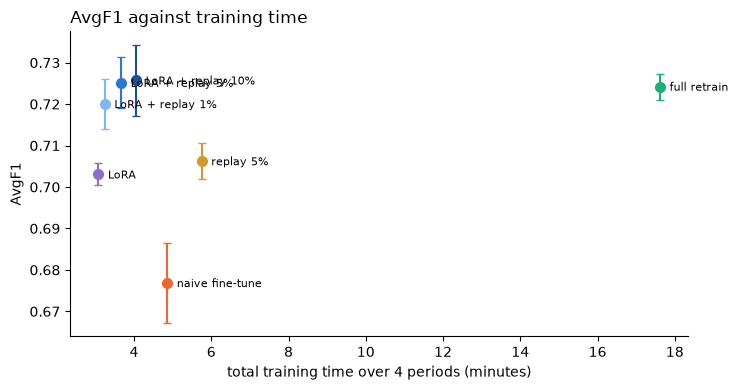

In [3]:
g = runs.groupby("method")
fig, ax = plt.subplots(figsize=(7.5, 4))
for method in order:
    ax.errorbar(
        g["minutes"].mean()[method],
        g["avg_f1"].mean()[method],
        yerr=g["avg_f1"].std()[method],
        fmt="o",
        color=COLORS[method],
        capsize=3,
        markersize=7,
    )
    ax.annotate(
        method,
        (g["minutes"].mean()[method], g["avg_f1"].mean()[method]),
        textcoords="offset points",
        xytext=(7, -3),
        fontsize=8,
    )
ax.set_xlabel("total training time over 4 periods (minutes)")
ax.set_ylabel("AvgF1")
ax.set_title("AvgF1 against training time", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

## 3. Does the model keep P1?

P1 test F1 after each step, mean over seeds. P1 is the period with the biggest loss for
naive fine-tuning.

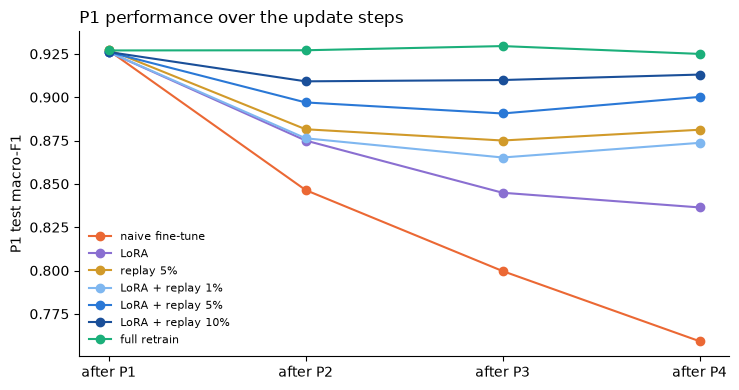

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for method in order:
    curve = np.mean(runs.loc[runs["method"] == method, "p1_by_step"].tolist(), axis=0)
    ax.plot(range(1, 5), curve, marker="o", color=COLORS[method], label=method)
ax.set_xticks(range(1, 5), ["after P1", "after P2", "after P3", "after P4"])
ax.set_ylabel("P1 test macro-F1")
ax.set_title("P1 performance over the update steps", loc="left")
ax.legend(fontsize=8, frameon=False, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

## 4. Targets from `docs/design.md` section 8

In [5]:
mean = runs.groupby("method")[["avg_f1", "forgetting", "last_step_s"]].mean()
full, naive = mean.loc["full retrain"], mean.loc["naive fine-tune"]
limits = {
    "AvgF1 at least (full - 0.03)": (full["avg_f1"] - 0.03, "avg_f1", "min"),
    "Forgetting below (naive / 2)": (naive["forgetting"] / 2, "forgetting", "max"),
    "Last step below (full / 2), s": (full["last_step_s"] / 2, "last_step_s", "max"),
}
table = {}
for method in order:
    table[method] = {
        name: (
            "pass"
            if (mean.loc[method, col] >= lim if kind == "min" else mean.loc[method, col] < lim)
            else "fail"
        )
        for name, (lim, col, kind) in limits.items()
    }
check = pd.DataFrame(table).T
check.columns = [
    f"{name}: {lim:.3f}" if lim < 100 else f"{name}: {lim:.0f}"
    for name, (lim, *_) in limits.items()
]
check

,AvgF1 at least (full - 0.03): 0.694,Forgetting below (naive / 2): 0.028,"Last step below (full / 2), s: 164"
naive fine-tune,fail,fail,pass
LoRA,pass,pass,pass
replay 5%,pass,pass,pass
LoRA + replay 1%,pass,pass,pass
LoRA + replay 5%,pass,pass,pass
LoRA + replay 10%,pass,pass,pass
full retrain,pass,pass,fail
